# K-Sil standard silhouette results

### K-Sil

In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances
from joblib import Parallel, delayed

class KSil:
    def __init__(self,
                 n_clusters=3,
                 init='random',
                 max_iter=100,
                 random_state=0,
                 init_temperature=1.0,
                 learning_rate=0.2,
                 tol=1e-4,
                 n_init=1, n_jobs=1):

        # Parameters
        self.n_clusters = int(n_clusters)     # Number of clusters
        self.init = init                      # Initialization method
        self.max_iter = int(max_iter)         # Maximum number of iterations
        self.init_temperature = float(init_temperature) # Initial temperature
        self.random_state = int(random_state) # Random seed
        self.learning_rate = learning_rate    # Learning rate for temperature
        self.tol = float(tol)                 # Centroid convergence tolerance

        # For multiple initializations:
        self.n_init = n_init                  # Number of initializations
        self.n_jobs = n_jobs                  # Number of cores

        # n_clusters check
        if self.n_clusters < 2:
           raise ValueError(f"n_clusters ({self.n_clusters}) must be > 1.")
        # init check
        if isinstance(self.init, str) and self.init not in ('random', 'k-means++'):
           raise ValueError(f"init ({self.init}) must be 'random' or 'k-means++'.")
        # n_init check
        if self.n_init < 1:
           raise ValueError(f"n_init ({self.n_init}) must be > 0.")

        # Attributes
        self.labels_ = None          # Cluster labels (converged partition)
        self.cluster_centers_ = None # Cluster centers (converged partition)
        self.n_iter_ = None          # Number of iterations (until convergence)
        self.sil_ = None             # silhouette (centroid-approximated) at converged partition

        # history attributes
        self.centers_history_ = None # Centroids across iterations
        self.labels_history_ = None  # Assignments across iterations
        self.sil_history_ = None     # Silhouette proxy across iterations
        self.weights_history_ = None # Weights across iterations

    def _initialization(self, X, n_clusters):
        X = np.asarray(X)
        if X.shape[0] < n_clusters:
           raise ValueError(f"n_clusters ({n_clusters}) can not exceed n_samples ({X.shape[0]}).")

        kmeans = KMeans(n_clusters=n_clusters,
                        init=self.init,
                        random_state=self.random_state,
                        n_init=1,
                        max_iter=1).fit(X)
        centers = kmeans.cluster_centers_
        labels = kmeans.labels_

        # Retry if some clusters are empty in the initial assignment
        if np.unique(labels).size < n_clusters:
           max_retries = 10 # 10 retries at max
           base_seed = self.random_state
           for attempt in range(1, max_retries + 1):
               seed = base_seed + attempt
               km = KMeans(n_clusters=n_clusters,
                           init=self.init,
                           random_state=seed,
                           n_init=1,
                           max_iter=1).fit(X)
               centers = km.cluster_centers_
               labels = km.labels_
               if np.unique(labels).size == n_clusters:
                  break
           else:
               raise ValueError(
                     f"KMeans (1-iter) initialization produced empty clusters after {max_retries} retries. "
                     f"Try a different random_state, or init='k-means++'.")
        return centers, labels

    def _fit_once(self, X, n_clusters, previous_centers, w):
        X = np.asarray(X)
        w = np.asarray(w)
        km = KMeans(
             n_clusters=n_clusters,
             init=previous_centers,
             n_init=1,
             max_iter=1,
             random_state=self.random_state)
        km.fit(X, sample_weight=w)

        centers = km.cluster_centers_
        labels = km.labels_
        return centers, labels

    @staticmethod
    def sil_scores(X, labels, centers):
        X = np.asarray(X, dtype=float)
        labels = np.asarray(labels, dtype=int)
        centers = np.asarray(centers, dtype=float)

        if len(X) == 0:
           raise ValueError("X is empty. Cannot compute silhouette scores.")

        n = X.shape[0]

        # Squared distances to all centroids
        D = euclidean_distances(X, centers, squared=True)

        # Distance to own centroid (a: intra cluster distance proxy)
        D_diag = D[np.arange(n), labels]  # a^2
        a_vals = np.sqrt(D_diag)  # a

        # Nearest other centroid distance (b: inter cluster distance)
        D_others = D.copy()
        D_others[np.arange(n), labels] = np.inf
        b_sq = D_others.min(axis=1)  # b^2
        b_vals = np.sqrt(b_sq)  # b

        # Silhouette surrogate (b-a)/[max{a,b}+epsilon]
        max_ab = np.maximum(np.maximum(a_vals, b_vals), 1e-12)
        s_vals = (b_vals - a_vals) / max_ab

        return s_vals, a_vals, b_vals

    @staticmethod
    def micro_sil(s_vals):
        s_vals = np.asarray(s_vals, dtype=float)
        if s_vals.size == 0:
           return 0.0
        return float(s_vals.mean())

    @staticmethod
    def macro_sil(s_vals, labels):
        s_vals = np.asarray(s_vals, dtype=float)
        labels = np.asarray(labels, dtype=int)

        if s_vals.size == 0 or labels.size == 0:
           return 0.0

        uniq, inv = np.unique(labels, return_inverse=True)
        if uniq.size == 0:
           return 0.0
        sum_per_cluster = np.bincount(inv, weights=s_vals)
        cnt_per_cluster = np.bincount(inv)

        valid = cnt_per_cluster > 0
        if not np.any(valid):
           return 0.0
        cluster_means = sum_per_cluster[valid] / cnt_per_cluster[valid]
        return float(cluster_means.mean())

    def _weights(self, s_vals, temperature):
        s_vals = np.asarray(s_vals, dtype=float)
        weights = np.exp(s_vals * temperature)
        return weights

    def _KSil(self, X, n_clusters, max_iter):

        # Initialize centroids
        centers, labels = self._initialization(X, n_clusters)
        tau = self.init_temperature # initial temperature
        prev_score =  None

        centers_history = [centers.copy()]
        labels_history = [labels.copy()]
        sil_history = []
        weights_history = []

        n_iter = 0

        while n_iter < max_iter:

            n_iter += 1

            # Compute point-silhouette scores
            sil_vals, a_vals, b_vals = KSil.sil_scores(X, labels, centers)
            score = KSil.macro_sil(sil_vals, labels)

            micro_sil = KSil.micro_sil(sil_vals)
            sil_history.append(micro_sil)

            # Update temperature
            if prev_score is not None:
               r = (score - prev_score) / max(1 - prev_score, 1e-12)

               r = float(np.clip(r, -1.0, 1.0))

               # data-driven bounds to avoid softmax saturation
               counts = np.bincount(labels, minlength=n_clusters)
               m_max = int(max(counts.max(), 2))
               L     = float(np.sqrt(2.0 * np.log(m_max)))
               z_max = (m_max - 1) / m_max
               tau_min, tau_max = 1e-12, L / max(z_max, 1e-8)

               # multiplicative update (no logs needed)
               eta = self.learning_rate # default: 0.2 (small stable learning rate)

               # Update temperature based on the rate of change of the silhouette objective
               tau = float(np.clip(tau * np.exp(eta * r), tau_min, tau_max))

            # store for next iteration’s drift calc
            prev_score = score

            # Retain previous centroids for convergence checking
            previous_centers = centers.copy()

            # Compute weights based on silhouette scores
            weights = self._weights(sil_vals, tau)

            weights_history.append(weights.copy())

            # Update centroids and assignments
            centers, labels = self._fit_once(X, n_clusters, previous_centers, weights)

            centers_history.append(centers.copy())
            labels_history.append(labels.copy())

            avg_move = np.linalg.norm(centers - previous_centers, axis=1).mean()

            # Centroid stability
            if avg_move < self.tol:
               break

        return centers, labels, n_iter, sil_history, centers_history, labels_history, weights_history

    def fit(self, X):
        """
        Run KSil on X and store the converged partition.
        X: array-like, shape (n_samples, n_features)
        """
        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)

        if self.n_init == 1:
           (centers,
           labels,
           n_iter,
           sil_history,
           centers_history,
           labels_history,
           weights_history) = self._KSil(X_arr, self.n_clusters, self.max_iter)
        else:
           base_seed = self.random_state
           seeds = [int(base_seed) + i for i in range(self.n_init)]

           # Helper: directly call _KSil with a seed
           def _run_one(seed):
               self.random_state = seed
               return self._KSil(X_arr, self.n_clusters, self.max_iter)

           if self.n_jobs in (None, 1):
              results = [_run_one(seed) for seed in seeds]
           else:
              results = Parallel(n_jobs=self.n_jobs)(delayed(_run_one)(seed) for seed in seeds)

           # Pick best run by final silhouette
           best_idx = None
           best_sil = -np.inf

           for i, res in enumerate(results):
               (_, _, _, sil_history_i,
               _, _, _) = res
               if sil_history_i:
                  final_sil_i = sil_history_i[-1]
               else:
                  final_sil_i = -np.inf
               if final_sil_i > best_sil:
                   best_sil = final_sil_i
                   best_idx = i

           (centers,
           labels,
           n_iter,
           sil_history,
           centers_history,
           labels_history,
           weights_history) = results[best_idx]

           self.random_state = base_seed # restore base random_state

        self.cluster_centers_ = centers
        self.labels_ = labels
        self.n_iter_ = n_iter

        self.sil_history_ = sil_history
        self.sil_ = sil_history[-1] if sil_history else None
        self.centers_history_ = centers_history
        self.labels_history_ = labels_history
        self.weights_history_ = weights_history

        return self

    def predict(self, X):
        """
        Assign new points to the nearest learned centroid.
        """
        if self.cluster_centers_ is None:
           raise ValueError("KSil model is not fitted yet. Call '.fit(...)' first.")

        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)
        dist_matrix = euclidean_distances(X_arr, self.cluster_centers_, squared=True)
        labels = np.argmin(dist_matrix, axis=1)
        return labels.astype(int)

    def transform(self, X):
        """
        Return distances of each sample to each centroid.
        """
        if self.cluster_centers_ is None:
           raise ValueError("KSil model is not fitted yet. Call '.fit(...)' first.")

        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)
        distances = euclidean_distances(X_arr, self.cluster_centers_, squared=False)
        return distances

    def fit_predict(self, X):
        """
        Equivalent to: fit(X); return labels_.
        """
        self.fit(X)
        return self.labels_

    def fit_transform(self, X):
        """
        Equivalent to: fit(X); return transform(X).
        """
        self.fit(X)
        return self.transform(X)

### Instance weights visualization on synthetic data

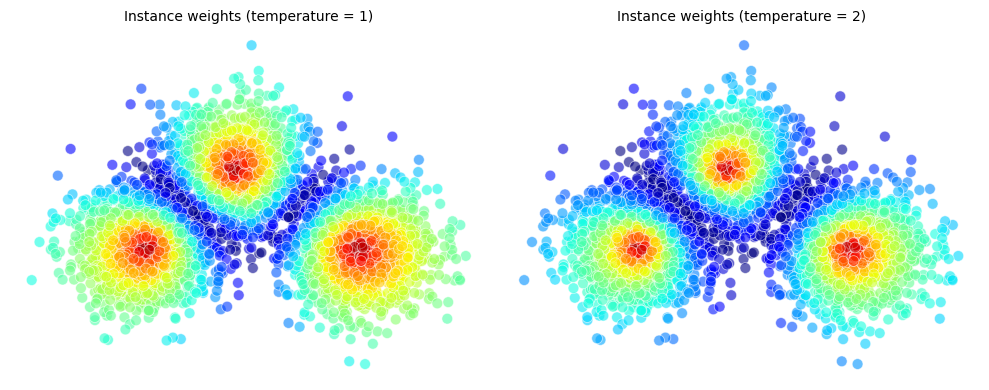

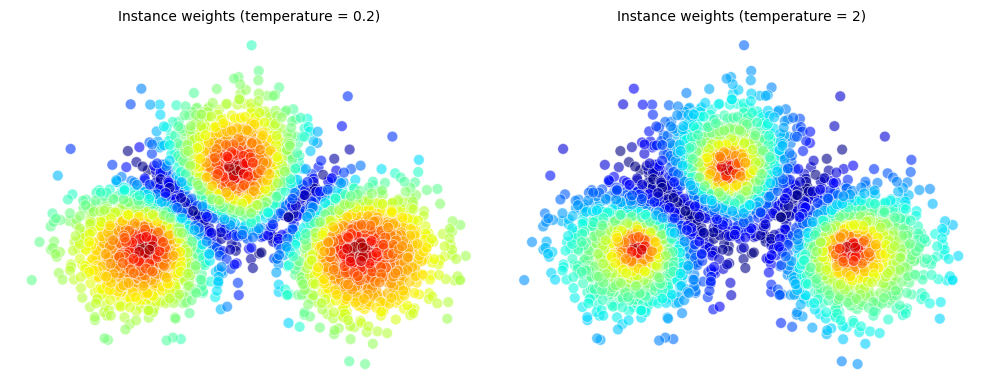

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

X, y_true = make_blobs(
    n_samples=4000,
    centers=[[0, 0], [5, 5], [12, 0]],
    cluster_std=2,
    random_state=42
)

n_clusters = 3
base_km = KMeans(
    n_clusters=n_clusters,
    init='random',
    random_state=0
).fit(X)

centers = base_km.cluster_centers_
labels = base_km.labels_

s_vals, a_vals, b_vals = KSil.sil_scores(X, labels, centers)

tau_low = 1
tau_high = 2

w_low = np.exp(s_vals * tau_low)
w_high = np.exp(s_vals * tau_high)

def normalize(v):
    v = np.asarray(v, dtype=float)
    v_min, v_max = v.min(), v.max()
    return (v - v_min) / (v_max - v_min + 1e-12)

w_low_norm = normalize(w_low)
w_high_norm = normalize(w_high)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

titles = [
    f"Instance weights (temperature = {tau_low})",
    f"Instance weights (temperature = {tau_high})"
]
weight_sets = [w_low_norm, w_high_norm]

scatter = None
for ax, w_norm, title in zip(axes, weight_sets, titles):
    scatter = ax.scatter(
        X[:, 0], X[:, 1],
        c=w_norm,
        cmap="jet",
        s=60,
        alpha=0.6,
        linewidth=0.6,
        edgecolor='w'
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()

plt.tight_layout()

plt.show()

tau_low = 0.2
tau_high = 2

w_low = np.exp(s_vals * tau_low)
w_high = np.exp(s_vals * tau_high)

def normalize(v):
    v = np.asarray(v, dtype=float)
    v_min, v_max = v.min(), v.max()
    return (v - v_min) / (v_max - v_min + 1e-12)

w_low_norm = normalize(w_low)
w_high_norm = normalize(w_high)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

titles = [
    f"Instance weights (temperature = {tau_low})",
    f"Instance weights (temperature = {tau_high})"
]
weight_sets = [w_low_norm, w_high_norm]

scatter = None
for ax, w_norm, title in zip(axes, weight_sets, titles):
    scatter = ax.scatter(
        X[:, 0], X[:, 1],
        c=w_norm,
        cmap="jet",
        s=60,
        alpha=0.6,
        linewidth=0.6,
        edgecolor='w'
    )
    ax.set_title(title, fontsize=10)
    ax.set_axis_off()

plt.tight_layout()

plt.show()

### Imports, helpers, baselines

##### Imports

In [3]:
!pip install ucimlrepo
import copy
import json
import math
import random
import re
import sys
import time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import wilcoxon
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from sklearn.base import BaseEstimator, ClusterMixin
from sklearn.covariance import LedoitWolf
from sklearn.datasets import (
    make_blobs,
    load_iris,
    load_wine,
    load_digits,
    load_breast_cancer,
    fetch_openml,
    fetch_20newsgroups,
)
from sklearn.decomposition import PCA
import umap
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    silhouette_samples,
    silhouette_score,
    davies_bouldin_score,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    pairwise_distances,
)
from sklearn.metrics import normalized_mutual_info_score as NMI
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    PowerTransformer,
    Normalizer,
    LabelEncoder,
    normalize,
)
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from joblib import Parallel, delayed
from ucimlrepo import fetch_ucirepo
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    pipeline,
)
from huggingface_hub import login
from getpass import getpass

import warnings
warnings.filterwarnings(
    "ignore",
    message=".*Duplicate values are leading to incorrect results.*",
    category=UserWarning
)

from google.colab import userdata
# Get HF token from Colab Secrets
hf_token = userdata.get('HF_TOKEN')
if not hf_token:
    raise ValueError("No secret named 'HF_TOKEN' found in Colab.")
login(token = hf_token.strip())

##### Silhouette Helper

In [4]:
#  Helper computation methods
class Silhouette:
    @staticmethod
    def Micro(X, labels):
        return silhouette_score(X, labels)

    @staticmethod
    def Macro(X, labels):
        silhouette_vals = silhouette_samples(X, labels)
        unique_labels = np.unique(labels)
        cluster_means = [
            np.mean(silhouette_vals[labels == lbl]) for lbl in unique_labels
        ]
        return np.mean(cluster_means) if cluster_means else 0

    @staticmethod
    def MacroApprox(X, labels, centers=None):
        X = np.asarray(X)
        y = np.asarray(labels).ravel()

        if X.ndim != 2:
            raise ValueError("X must be a 2D array of shape (n_samples, n_features).")
        n_samples, n_features = X.shape
        if n_samples == 0:
            return 0.0

        unique_labels, inv = np.unique(y, return_inverse=True)
        k = unique_labels.size
        if k < 2:
            return 0.0

        if centers is None:
            counts = np.bincount(inv, minlength=k).astype(float)
            sums = np.zeros((k, n_features), dtype=float)
            np.add.at(sums, inv, X)
            centers_mat = sums / counts[:, None]
        else:
            centers = np.asarray(centers, dtype=float)
            if centers.ndim != 2 or centers.shape[1] != n_features:
                raise ValueError(f"`centers` must have shape (k, d) with d={n_features}.")
            if centers.shape[0] != k:
                raise ValueError(f"`centers` first dimension must equal number of clusters k={k}.")
            if not np.array_equal(unique_labels, np.arange(k)):
                raise ValueError(
                    "When passing `centers` as ndarray, cluster labels must be 0..k-1 "
                    "so that centers[row] corresponds to that label."
                )
            centers_mat = centers

        D_sq = euclidean_distances(X, centers_mat, squared=True)

        a = np.sqrt(D_sq[np.arange(n_samples), inv])
        D_sq[np.arange(n_samples), inv] = np.inf
        b = np.sqrt(D_sq.min(axis=1))

        denom = np.maximum(np.maximum(a, b), 1e-12)
        s_point = (b - a) / denom

        cluster_sizes = np.bincount(inv, minlength=k).astype(float)
        s_point[cluster_sizes[inv] == 1] = 0.0

        sum_by_cluster = np.bincount(inv, weights=s_point, minlength=k)
        mean_by_cluster = sum_by_cluster / np.maximum(cluster_sizes, 1.0)
        return float(mean_by_cluster.mean())

    @staticmethod
    def MicroApprox(X, labels, centers=None):
        X = np.asarray(X)
        y = np.asarray(labels).ravel()

        if X.ndim != 2:
            raise ValueError("X must be a 2D array of shape (n_samples, n_features).")
        n_samples, n_features = X.shape
        if n_samples == 0:
            return 0.0

        unique_labels, inv = np.unique(y, return_inverse=True)
        k = unique_labels.size
        if k < 2:
            return 0.0

        if centers is None:
            counts = np.bincount(inv, minlength=k).astype(float)
            sums = np.zeros((k, n_features), dtype=float)
            np.add.at(sums, inv, X)
            centers_mat = sums / counts[:, None]
        else:
            centers = np.asarray(centers, dtype=float)
            if centers.ndim != 2 or centers.shape[1] != n_features:
                raise ValueError(f"`centers` must have shape (k, d) with d={n_features}.")
            if centers.shape[0] != k:
                raise ValueError(f"`centers` first dimension must equal number of clusters k={k}.")
            if not np.array_equal(unique_labels, np.arange(k)):
                raise ValueError(
                    "When passing `centers` as ndarray, cluster labels must be 0..k-1 "
                    "so that centers[row] corresponds to that label."
                )
            centers_mat = centers

        D_sq = euclidean_distances(X, centers_mat, squared=True)

        a = np.sqrt(D_sq[np.arange(n_samples), inv])
        D_sq[np.arange(n_samples), inv] = np.inf
        b = np.sqrt(D_sq.min(axis=1))

        denom = np.maximum(np.maximum(a, b), 1e-12)
        s_point = (b - a) / denom

        return float(s_point.mean())

#### Baselines

##### LOFKMeans

In [5]:
#  lofkmeans baseline
class LOFKMeans(BaseEstimator, ClusterMixin):
    """
    LOF-weighted KMeans
    """
    def __init__(self, n_clusters=3,
                 lof_neighbors=5,
                 random_state=None,
                 max_iter=100):
        self.n_clusters    = n_clusters
        self.lof_neighbors = lof_neighbors
        self.random_state  = random_state
        self.kmeans_       = None
        self.weights_      = None
        self.lof_scores_   = None
        self.labels_ = None
        self.cluster_centers_ = None
        self.max_iter=max_iter

    def _compute_lof_weights(self, X, n_neighbors):
        lof = LocalOutlierFactor(n_neighbors=n_neighbors)
        lof.fit(X)
        lof_scores = -lof.negative_outlier_factor_
        mn, mx = lof_scores.min(), lof_scores.max()
        w = 1 - (lof_scores - mn) / (mx - mn + 1e-6)
        return w

    def fit(self, X, y=None):
        Xs = np.asarray(X)
        # weights and kmeans
        self.weights_ = self._compute_lof_weights(Xs, self.lof_neighbors)
        self.kmeans_ = KMeans(n_clusters=self.n_clusters,
                              init="random",
                              n_init=1,
                              random_state=self.random_state,
                              max_iter=self.max_iter).fit(
                                  Xs, sample_weight=self.weights_)
        self.labels_ = self.kmeans_.labels_
        self.cluster_centers_ = self.kmeans_.cluster_centers_
        return self

    def fit_predict(self, X, y=None):
        return self.fit(X).labels_

##### Iterative LOFKMeans

In [6]:
# Iterative lofkmeans baseline
class ILOFKMeans:

    def __init__(self,
                 n_clusters=3,
                 init='random',
                 max_iter=100,
                 random_state=0,
                 tol=1e-4,
                 lof_neighbors=5):

        self.n_clusters   = int(n_clusters)
        self.init         = init
        self.max_iter     = int(max_iter)
        self.random_state = int(random_state)
        self.tol          = float(tol)
        self.lof_neighbors = int(lof_neighbors)

        self.labels_ = None
        self.cluster_centers_ = None
        self.n_iter_ = None

    def _initialization(self, X, n_clusters):
        X = np.asarray(X)
        if X.shape[0] < n_clusters:
            raise ValueError(
                f"n_clusters ({n_clusters}) can not exceed n_samples ({X.shape[0]})."
            )

        kmeans = KMeans(
            n_clusters=n_clusters,
            init=self.init,
            random_state=self.random_state,
            n_init=1,
            max_iter=1
        ).fit(X)

        centers = kmeans.cluster_centers_
        labels = kmeans.labels_

        if np.unique(labels).size < n_clusters:
            max_retries = 10
            base_seed = self.random_state
            for attempt in range(1, max_retries + 1):
                seed = base_seed + attempt
                km = KMeans(
                    n_clusters=n_clusters,
                    init=self.init,
                    random_state=seed,
                    n_init=1,
                    max_iter=1
                ).fit(X)
                centers = km.cluster_centers_
                labels = km.labels_
                if np.unique(labels).size == n_clusters:
                    break
            else:
                raise ValueError(
                    "KMeans (1-iter) initialization produced empty clusters "
                    f"after {max_retries} retries. Try a different random_state, "
                    "or init='k-means++'."
                )

        return centers, labels

    def _fit_once(self, X, n_clusters, previous_centers, w):
        X = np.asarray(X)
        w = np.asarray(w)

        km = KMeans(
            n_clusters=n_clusters,
            init=previous_centers,
            n_init=1,
            max_iter=1,
            random_state=self.random_state
        )
        km.fit(X, sample_weight=w)

        centers = km.cluster_centers_
        labels = km.labels_
        return centers, labels

    def _clusterwise_lof_weights(self, X, labels):

        X = np.asarray(X)
        labels = np.asarray(labels, dtype=int)
        n = X.shape[0]

        weights = np.zeros(n, dtype=float)
        lof_scores_all = np.zeros(n, dtype=float)

        for k in range(self.n_clusters):
            idx = np.where(labels == k)[0]
            if idx.size == 0:
                continue

            n_neighbors = min(self.lof_neighbors, idx.size - 1)
            if n_neighbors < 1:

                weights[idx] = 1.0
                lof_scores_all[idx] = 0.0
                continue

            Xk = X[idx]
            lof = LocalOutlierFactor(
                n_neighbors=n_neighbors,
                novelty=False
            )
            lof.fit(Xk)

            lof_scores = -lof.negative_outlier_factor_
            lof_scores_all[idx] = lof_scores

            mn, mx = lof_scores.min(), lof_scores.max()
            if mx - mn < 1e-12:

                wk = np.ones_like(lof_scores)
            else:
                scaled = (lof_scores - mn) / (mx - mn + 1e-6)

                wk = 1.0 - scaled

            weights[idx] = wk

        return weights, lof_scores_all

    def _ILOFKM(self, X, n_clusters, max_iter):
        X = np.asarray(X)
        centers, labels = self._initialization(X, n_clusters)
        n_iter = 0

        while n_iter < max_iter:
            n_iter += 1

            weights, lof_scores = self._clusterwise_lof_weights(X, labels)

            previous_centers = centers.copy()

            centers, labels = self._fit_once(
                X, n_clusters, previous_centers, weights
            )

            avg_move = np.linalg.norm(
                centers - previous_centers, axis=1
            ).mean()
            if avg_move < self.tol:
                break

        return centers, labels, n_iter

    def fit(self, X):
        X_arr = X.values if hasattr(X, "values") else np.asarray(X, dtype=float)
        (centers,labels,n_iter) = self._ILOFKM(X_arr, self.n_clusters, self.max_iter)

        self.cluster_centers_ = centers
        self.labels_ = labels
        self.n_iter_ = n_iter

        return self

##### OWKMeans

In [7]:
class CentroidSilhouetteOWKMeansFast:
    """
    Centroid-silhouette OW K-means (fast Lloyd-style inner loop).

    - Objective: weighted K-means SSE
    - Weights: silhouette-based with centroid proxy from KSil.sil_scores,
      then w_i = (1 - s_i) / 2, optionally rescaled per cluster (Constraint B).
    """

    def __init__(
        self,
        n_clusters=3,
        max_iter=10,        # outer iterations (weights-clustering alternations)
        inner_max_iter=2,   # Lloyd steps per outer iter (in KMeans)
        random_state=None,
        tol=1e-4,           # convergence tolerance on centroid movement
        constraint_B=True,
    ):
        self.n_clusters = int(n_clusters)
        self.max_iter = int(max_iter)
        self.inner_max_iter = int(inner_max_iter)
        self.random_state = None if random_state is None else int(random_state)
        self.tol = float(tol)
        self.constraint_B = bool(constraint_B)

        self.labels_ = None
        self.cluster_centers_ = None   # weighted centers
        self.sample_weights_ = None    # final w_i
        self.n_iter_ = None


    def _check_X(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")
        n_samples = X.shape[0]
        if self.n_clusters < 1 or self.n_clusters > n_samples:
            raise ValueError(
                f"n_clusters={self.n_clusters} must be in [1, n_samples={n_samples}]"
            )
        return X

    def _compute_weights(self, X, labels, centers):
        """
        Silhouette-based weights from KSil.sil_scores with optional Constraint B.
        """

        X = np.asarray(X, float)
        labels = np.asarray(labels, int)
        K = centers.shape[0]

        s_vals, a_vals, b_vals = KSil.sil_scores(X, labels, centers)

        # singleton clusters: s_i = 0 for those points
        counts = np.bincount(labels, minlength=K)
        s_vals[counts[labels] <= 1] = 0.0

        # w_i = (1 - s_i)/2 in [0, 1]
        w_raw = (1.0 - s_vals) / 2.0
        w_raw = np.clip(w_raw, 0.0, 1.0)

        if not self.constraint_B:
            return w_raw

        # Constraint B: sum_{i in S_k} w_i = n_k
        w = np.zeros_like(w_raw)
        for k in range(K):
            mask = (labels == k)
            if not np.any(mask):
                continue
            wk = w_raw[mask]
            sum_wk = wk.sum()
            n_k = mask.sum()
            if sum_wk <= 0:
                w[mask] = 1.0
            else:
                w[mask] = wk * (n_k / sum_wk)
        return w

    def fit(self, X):
        """
        Fit centroid-silhouette OW K-means (Lloyd-style inner loop).
        """
        X = self._check_X(X)
        n, d = X.shape
        K = self.n_clusters

        # Initial plain K-means (unweighted)
        km = KMeans(
            n_clusters=K,
            init="random",
            n_init=1,
            max_iter=1,
            random_state=self.random_state,
        ).fit(X)
        labels = km.labels_
        centers = km.cluster_centers_

        prev_centers = centers.copy()
        self.n_iter_ = self.max_iter

        # Outer loop: recompute weights re-run weighted KMeans
        for it in range(self.max_iter):

            # silhouette-based weights from current labels and centers
            w = self._compute_weights(X, labels, centers)

            # run Lloyd (KMeans) with fixed weights in C
            km_w = KMeans(
                n_clusters=K,
                init=centers,          # warm-start from previous centers
                n_init=1,
                max_iter=self.inner_max_iter,
                random_state=self.random_state,
            ).fit(X, sample_weight=w)

            labels = km_w.labels_
            centers = km_w.cluster_centers_

            # check convergence of centroids
            move = np.linalg.norm(centers - prev_centers, axis=1).mean()
            if move < self.tol:
                self.n_iter_ = it + 1
                break
            prev_centers = centers.copy()

        # Final weights + weighted centers
        w_final = self._compute_weights(X, labels, centers)

        sum_w = np.bincount(labels, weights=w_final, minlength=K)
        sum_wx = np.zeros((K, d), dtype=float)
        for k in range(K):
            mask = (labels == k)
            if not np.any(mask):
                continue
            wk = w_final[mask]
            Xi = X[mask]
            sum_wx[k] = (wk[:, None] * Xi).sum(axis=0)

        centers_w = centers.copy()
        for k in range(K):
            if sum_w[k] > 0:
                centers_w[k] = sum_wx[k] / sum_w[k]

        self.labels_ = labels
        self.sample_weights_ = w_final
        self.cluster_centers_ = centers_w

        return self

### Comparison

#### Methods

##### SIL, ACC, NMI, ARI, AMI, DB, Runtime (s)

In [8]:
def _t_ci(x, alpha=0.05, clip_lower=True, clip_higher=True):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = x.size
    m = float(np.mean(x)) if n else np.nan
    if n < 2:
        return m, m
    se = np.std(x, ddof=1) / np.sqrt(n)
    tcrit = stats.t.ppf(1 - alpha/2, df=n-1)
    lo = m - tcrit * se
    hi = m + tcrit * se
    if clip_lower and clip_higher:
       lo = max(lo, 0.000)
       hi = min(hi, 1.000)

    return lo, hi

def clustering_accuracy(y_true, y_pred):
    # Build confusion matrix (rows=true labels, columns=predicted clusters)
    cm = confusion_matrix(y_true, y_pred)

    # We want to maximize correct assignments, but linear_sum_assignment solves a minimum problem,
    # so pass the cost matrix as (total_samples - cm)
    cost_matrix = cm.max() - cm

    # Hungarian algorithm finds the minimal total cost assignment
    row_ind, col_ind = linear_sum_assignment(cost_matrix)

    # Sum up the matches from the confusion matrix
    total_correct = cm[row_ind, col_ind].sum()

    acc = total_correct / y_true.shape[0]

    return float(np.clip(acc, 0.0, 1.0))


def evaluation(
    X,
    y,
    dataset_name='Dataset',
    k=2,
    seeds=range(0, 5),
    approx=False,
    temp=1
):

    results_sil = []

    for seed in seeds:

        kmeans = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=1,
            init='random',
            max_iter=100
        ).fit(X)

        s_kmeans = Silhouette.Micro(
            X,
            kmeans.labels_
        )

        lofkmeans = LOFKMeans(
            n_clusters=k,
            random_state=seed
        ).fit(X)

        s_lofkmeans = Silhouette.Micro(
            X,
            lofkmeans.labels_
        )

        ilofkmeans = ILOFKMeans(
            n_clusters=k,
            random_state=seed
        ).fit(X)

        s_ilofkmeans = Silhouette.Micro(
            X,
            ilofkmeans.labels_
        )


        dwkm = CentroidSilhouetteOWKMeansFast(
            n_clusters=k,
            random_state=seed,
            constraint_B=True
        ).fit(X)

        s_dwkm = Silhouette.Micro(
            X,
            dwkm.labels_
        )


        ksil = KSil(
            n_clusters=k,
            random_state=seed,
            init_temperature=temp
        ).fit(X)

        s_ksil = Silhouette.Micro(
            X,
            ksil.labels_
        )

        results_sil.append({
            'Dataset': dataset_name,
            'k': k,
            'Seed': seed,
            'S_exact_kmeans': s_kmeans,
            'S_exact_lofkmeans': s_lofkmeans,
            'S_exact_ilofkmeans': s_ilofkmeans,
            'S_exact_dwkm': s_dwkm,
            'S_exact_KSil': s_ksil
        })


    df_results_sil = pd.DataFrame(results_sil)

    methods = {
        'k-means': 'S_exact_kmeans',
        'LOFKMeans': 'S_exact_lofkmeans',
        'iLOFKMeans': 'S_exact_ilofkmeans',
        'OWKMeans': 'S_exact_dwkm',
        'K-Sil': 'S_exact_KSil'
    }

    summary = {
        'Dataset': dataset_name,
        'k': k
    }

    for method, column in methods.items():

        values = df_results_sil[column].values

        mean_sil = float(
            np.mean(values)
        )

        ci_low, ci_high = _t_ci(
            values,
            alpha=0.05,
            clip_lower=False
        )

        summary[f'Mean SIL ({method})'] = mean_sil

        summary[f'95% CI ({method})'] = (
            ci_low,
            ci_high
        )

    sil_df = pd.DataFrame([summary])

    print()
    print("=" * 90)
    print(f"EXACT SILHOUETTE — {dataset_name}")
    print(f"Seeds: {len(df_results_sil)}")
    print("=" * 90)

    mean_cols = [
        c for c in sil_df.columns
        if c.startswith('Mean SIL')
    ]

    ci_cols = [
        c for c in sil_df.columns
        if c.startswith('95% CI')
    ]

    display(
        sil_df.style.format({
            **{
                c: '{:.6f}'.format
                for c in mean_cols
            },
            **{
                c: (
                    lambda t:
                    f'({t[0]:.6f}, {t[1]:.6f})'
                )
                for c in ci_cols
            }
        })
    )

    return sil_df

seed_range = range(0, 10)

#### Results

##### Wine

In [17]:
from sklearn.datasets import load_iris, load_wine
from sklearn.preprocessing import StandardScaler
import pandas as pd

data = load_wine()
X_wine = data.data
y_wine = data.target
X_wine = StandardScaler().fit_transform(X_wine)

In [18]:
results_wine = evaluation(X_wine , y_wine,'Wine', len(np.unique(y_wine)), range(0,25), approx=False, temp=2)


EXACT SILHOUETTE — Wine
Seeds: 25


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,Wine,3,0.277961,"(0.268441, 0.287481)",0.274107,"(0.257177, 0.291036)",0.278632,"(0.269172, 0.288091)",0.279350,"(0.270699, 0.288001)",0.284921,"(0.284692, 0.285151)"


##### Breast Cancer

In [19]:
from sklearn.datasets import load_iris, load_wine, load_breast_cancer
from sklearn.preprocessing import StandardScaler
import pandas as pd

data = load_breast_cancer()
X_bc = data.data
y_bc = data.target

X_bc = StandardScaler().fit_transform(X_bc)

In [20]:
results_bc = evaluation(X_bc, y_bc, 'Breast Cancer', len(np.unique(y_bc)), seed_range,approx=False, temp=2)


EXACT SILHOUETTE — Breast Cancer
Seeds: 10


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,Breast Cancer,2,0.343438,"(0.342857, 0.344019)",0.342133,"(0.341946, 0.342320)",0.342176,"(0.341917, 0.342435)",0.344251,"(0.343535, 0.344968)",0.346571,"(0.346571, 0.346571)"


##### Vehicle

In [21]:
data_vehicle = fetch_openml(name="vehicle", version=1, as_frame=False)
X_vehicle_raw = data_vehicle.data
y_vehicle_txt = data_vehicle.target

le = LabelEncoder()
y_vehicle = le.fit_transform(np.asarray(y_vehicle_txt))

imputer = SimpleImputer(strategy='mean')
X_vehicle_imputed = imputer.fit_transform(X_vehicle_raw)

scaler = StandardScaler()
X_vehicle_scaled = scaler.fit_transform(X_vehicle_imputed)

reducer = umap.UMAP(n_components=15, n_neighbors=10, min_dist=0.0, random_state=42)
X_vehicle_umap = reducer.fit_transform(X_vehicle_scaled)

X_vehicle = X_vehicle_umap

k_vehicle = len(np.unique(y_vehicle))
name_vehicle = "Vehicle"

print(f"Dataset: {name_vehicle}")
print(f"Shape: {X_vehicle.shape}")
print(f"K: {k_vehicle}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Dataset: Vehicle
Shape: (846, 15)
K: 4


In [22]:
vehicle_res = evaluation(X_vehicle, y_vehicle, 'vehicle', k_vehicle, range(0,10), False)


EXACT SILHOUETTE — vehicle
Seeds: 10


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,vehicle,4,0.496148,"(0.457751, 0.534546)",0.497526,"(0.455612, 0.539441)",0.495995,"(0.457761, 0.534230)",0.510155,"(0.470053, 0.550257)",0.495758,"(0.458641, 0.532876)"


##### HTRU2

In [23]:
htru2 = fetch_ucirepo(id=372)
X_htru2 = htru2.data.features.to_numpy()
y_raw_htru2 = htru2.data.targets.iloc[:, 0]

le_htru2 = LabelEncoder()
y_htru2 = le_htru2.fit_transform(y_raw_htru2)
num_classes_htru2 = len(np.unique(y_htru2))

X_htru2_scaled = StandardScaler().fit_transform(X_htru2)
X_htru2 = X_htru2_scaled
y_htru2 = y_htru2
k_htru2 = num_classes_htru2
name_htru2 = "HTRU2"
print(f"Dataset: {name_htru2}\nShape: {X_htru2.shape}\nK: {k_htru2}")

Dataset: HTRU2
Shape: (17898, 8)
K: 2


In [24]:
htr_results = evaluation(X_htru2, y_htru2, dataset_name=name_htru2, k=k_htru2, seeds=seed_range, approx=False)


EXACT SILHOUETTE — HTRU2
Seeds: 10


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,HTRU2,2,0.607343,"(0.597848, 0.616839)",0.604241,"(0.597017, 0.611465)",0.607471,"(0.597872, 0.617069)",0.597058,"(0.595597, 0.598520)",0.640032,"(0.639807, 0.640257)"


##### SMS

In [25]:
encoder_minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

def build_minilm_pca_features(
    texts,
    n_components=50,
    encoder=encoder_minilm,
    random_state=0,
):
    """
    texts -> MiniLM embeddings -> PCA(n_components) -> L2-normalized
    """
    X_emb = encoder.encode(
        list(map(str, texts)),
        convert_to_numpy=True,
        show_progress_bar=True
    ).astype(np.float64)

    pca = PCA(
        n_components=n_components,
        whiten=False,
        random_state=random_state
    )
    X_pca = pca.fit_transform(X_emb)

    normalizer = Normalizer(norm="l2", copy=False)
    X_final = normalizer.fit_transform(X_pca)

    return X_final, pca, normalizer

ds_sms = load_dataset("ucirvine/sms_spam", split="train")

texts_sms  = list(map(str, ds_sms["sms"]))
labels_sms_raw = list(ds_sms["label"])

le_sms = LabelEncoder()
y_sms = le_sms.fit_transform(labels_sms_raw)
k_sms = len(np.unique(y_sms))

print(f"SMS Spam: {len(texts_sms)} msgs, {k_sms} classes (ham/spam)")

X_sms_minilm, pca_sms, norm_sms_emb = build_minilm_pca_features(
    texts_sms,
    n_components=100,
    encoder=encoder_minilm,
    random_state=0,
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/4.98k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  359kB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/5574 [00:00<?, ? examples/s]

SMS Spam: 5574 msgs, 2 classes (ham/spam)


Batches:   0%|          | 0/175 [00:00<?, ?it/s]

In [26]:
_ = evaluation(
    X_sms_minilm,
    y_sms,
    dataset_name="SMS",
    k=k_sms,
    seeds=range(0,25),
    approx=False, temp=2
)


EXACT SILHOUETTE — SMS
Seeds: 25


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,SMS,2,0.045278,"(0.045278, 0.045278)",0.045278,"(0.045278, 0.045278)",0.045278,"(0.045278, 0.045278)",0.045188,"(0.045178, 0.045197)",0.045263,"(0.045263, 0.045263)"


##### MINDS-14

In [27]:
ds_minds_train = load_dataset("DeepPavlov/minds14", split="train")
ds_minds_test  = load_dataset("DeepPavlov/minds14", split="test")

texts_minds = (
    list(map(str, ds_minds_train["utterance"])) +
    list(map(str, ds_minds_test["utterance"]))
)
labels_minds_raw = (
    list(ds_minds_train["label"]) +
    list(ds_minds_test["label"])
)

le_minds = LabelEncoder()
y_minds = le_minds.fit_transform(labels_minds_raw)
k_minds = len(np.unique(y_minds))

print(f"MINDS-14: {len(texts_minds)} docs, {k_minds} classes")

X_minds_minilm, pca_minds, norm_minds_emb = build_minilm_pca_features(
    texts_minds,
    n_components=100,
    encoder=encoder_minilm,
    random_state=0,
)

README.md:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 19.0kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.43kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/431 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/108 [00:00<?, ? examples/s]

MINDS-14: 539 docs, 14 classes


Batches:   0%|          | 0/17 [00:00<?, ?it/s]

In [28]:
_ = evaluation(
    X_minds_minilm,
    y_minds,
    dataset_name="MINDS-14",
    k=k_minds,
    seeds=range(0,25),
    approx=False, temp=2
)


EXACT SILHOUETTE — MINDS-14
Seeds: 25


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,MINDS-14,14,0.230884,"(0.221340, 0.240428)",0.231044,"(0.223321, 0.238766)",0.225693,"(0.215134, 0.236252)",0.228697,"(0.219100, 0.238294)",0.247637,"(0.239864, 0.255409)"


##### R8

In [31]:
from datasets import load_dataset
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
import numpy as np

ds_r8 = load_dataset("dxgp/R8")
texts_r8 = ds_r8["train"]["text"]
labels_r8 = ds_r8["train"]["label"]

le = LabelEncoder()
y_r8 = le.fit_transform(labels_r8)
k_r8 = len(np.unique(y_r8))
name_r8 = "R8"

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

X_emb_r8 = model.encode(
    list(texts_r8),
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=False,
)

print(f"Embeddings shape before PCA: {X_emb_r8.shape}")

pca = PCA(n_components=20, random_state=0)
X_r8_pca = pca.fit_transform(X_emb_r8)
y_r8 = y_r8

print(f"Dataset: {name_r8}, Shape after PCA: {X_r8_pca.shape}, k: {k_r8}")

train.csv:   0%|          | 0.00/3.02M [00:00<?, ?B/s]

val.csv:   0%|          | 0.00/340k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4936 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/549 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2189 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/155 [00:00<?, ?it/s]

Embeddings shape before PCA: (4936, 384)
Dataset: R8, Shape after PCA: (4936, 20), k: 8


In [32]:
res = evaluation(
    X_r8_pca,
    y_r8,
    dataset_name=name_r8,
    k=k_r8,
    seeds=range(0, 10),
    approx=False,
)


EXACT SILHOUETTE — R8
Seeds: 10


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,R8,8,0.149812,"(0.140092, 0.159533)",0.153391,"(0.147681, 0.159100)",0.148366,"(0.139842, 0.156890)",0.141011,"(0.131811, 0.150211)",0.152785,"(0.142879, 0.162692)"


##### Banking77

In [33]:
import numpy as np
from datasets import load_dataset
from sklearn.preprocessing import LabelEncoder, Normalizer
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer

ds_train = load_dataset("PolyAI/banking77", split="train", revision="refs/convert/parquet")
ds_test  = load_dataset("PolyAI/banking77", split="test",  revision="refs/convert/parquet")

texts_b77 = list(map(str, ds_train["text"])) + list(map(str, ds_test["text"]))
labels_b77_raw = list(ds_train["label"]) + list(ds_test["label"])

le = LabelEncoder()
y_b77 = le.fit_transform(labels_b77_raw)

k_b77 = len(np.unique(y_b77))
name_b77 = "BANKING77"

encoder_b77 = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
X_b77_embed = encoder_b77.encode(
    texts_b77,
    convert_to_numpy=True,
    show_progress_bar=False
).astype(np.float64)

pca_b77 = PCA(
    n_components=50,
    whiten=False,
    random_state=0
)
X_b77_pca = pca_b77.fit_transform(X_b77_embed)

normalizer = Normalizer(norm="l2", copy=False)
X_b77 = normalizer.fit_transform(X_b77_pca)

print(f"Dataset: {name_b77}")
print(f"Shape: {X_b77.shape}")
print(f"K (true classes): {k_b77}")

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

default/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

default/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Dataset: BANKING77
Shape: (13083, 50)
K (true classes): 77


In [34]:
pca_b77 = PCA(
    n_components=20,
    whiten=False,
    random_state=0
)

X_b77_pca = pca_b77.fit_transform(X_b77_embed)

normalizer = Normalizer(norm="l2", copy=False)
X_b77 = normalizer.fit_transform(X_b77_pca)

banking_results = evaluation(X_b77, y_b77, dataset_name=name_b77, k=k_b77, seeds=seed_range, approx=False)


EXACT SILHOUETTE — BANKING77
Seeds: 10


,Dataset,k,Mean SIL (k-means),95% CI (k-means),Mean SIL (LOFKMeans),95% CI (LOFKMeans),Mean SIL (iLOFKMeans),95% CI (iLOFKMeans),Mean SIL (OWKMeans),95% CI (OWKMeans),Mean SIL (K-Sil),95% CI (K-Sil)
0,BANKING77,77,0.192669,"(0.187785, 0.197553)",0.188107,"(0.183949, 0.192265)",0.190598,"(0.186015, 0.195181)",0.188140,"(0.182872, 0.193408)",0.193392,"(0.188764, 0.198019)"
